In [1]:
source('../../../R/preamble.R')

discrete_pal = c('#3B9AB2', '#7D3C98', '#EBCC2A', '#95A5A6', '#F21A00', '#27AE60')

library(rjson)

RESULTS = '../../../datasets/genomics/08_convergence/results/cosine_similarities/'

# Draw trees

In [2]:
reactor_order = c('E', 'H', 'F', 'G', 'D', 'C', 'B', 'A')
lwd = 0.5
ps = 1.2
wt_color = 'grey30'

In [3]:
segments = 

    # Start with complete grid
    expand_grid(
        r = c('E', 'H', 'F', 'G', 'D', 'C', 'B', 'A'),
        start = 0:23
    ) %>% 
    mutate(
        r = fct_relevel(r, reactor_order),
        rend = r, end = start+1
    ) %>% 

    # Make holes for discontinuities
    mutate(
        r = case_when(
            (r == 'H' & start == 8) ~ 'F',
            (r == 'E' & start == 12) ~ 'H',
            (r == 'G' & start == 13) ~ 'F',
            T ~ r
        ),
        r = fct_relevel(r, reactor_order),
    ) %>% 

    # Add population names
    mutate(
        pop = case_when(
            (rend == 'E' & start < 12) ~ 'X',
            (rend == 'G' & start < 13) ~ 'Y',
            (rend == 'H' & start < 8) ~ 'Z',
            T ~ r
        )
    ) %>% 
    mutate(r_id = as.numeric(r), rend_id = as.numeric(rend))

In [4]:
# Histogram of the null distribution, with the observed similarity and two-sided permutation p-value (from N2)
null_plot = function(name, level, label_y, hjust = 0, bins = 30) {
    results = fromJSON(file = paste0(RESULTS, name, '_', level, '.json'))
    null = results$null_distribution
    obs = results$observed
    offset = ifelse(hjust == 0, 1, -1) * 0.02 * diff(range(c(null, obs)))

    ggplot() +
        geom_histogram(
            aes(x = null, y = 100*after_stat(count/sum(count))),
            lwd = 0.3, col = 'grey40', fill = 'grey70', bins = bins
        ) +
        geom_vline(xintercept = obs) +
        add_text(obs + offset, label_y, paste0('Observed\np=', signif(results$p_value, 2)), hjust = hjust, size = 3) +
        ycont(0, NA) +
        labs(x = ifelse(level == 'gene', 'Gene-level similarity', 'COG-level similarity'), y = 'Null freq. (%)')
}

# F vs H

In [5]:
tree_plot_FH =
segments %>% 
    mutate(
        branch = case_when(
            (start > 8 & pop %in% c('E','H')) ~ 'branch1',
            (start > 8 & pop %in% c('F','G')) ~ 'branch2',
            (start > 8) ~ 'other',
            T ~ 'none'
        )
    ) %>% 

    ggplot() + aes(
        x = start*2.5, xend = end*2.5, 
        y = r, yend = rend, 
        col = branch) +

    scale_color_manual(values = c('none'='grey80', 'branch1'=discrete_pal[1], 'branch2'=discrete_pal[5], 'other'='grey20')) +

    scale_x_continuous(breaks = seq(0, 60, 15)) +
    coord_cartesian(xlim = c(0,62), ylim = c(0.8, 8.2), expand = c(0,0)) +

    theme(
        axis.line = eb, axis.ticks = eb, axis.text.y = eb, axis.title.y = eb, panel.grid = eb, 
        #axis.text.x = element_text(size=7),
        #axis.title.x = element_text(size=28, family='Ubuntu Mono'),
        #axis.title.x = eb
         ) +
    nl +

    geom_segment(lwd=lwd, lineend = 'round') +

    # Transfer time change
    annotate(geom = 'segment', x = 19, xend = 19, y = 0, yend = 9, lty = 3, lwd = 0.3, col = 'grey30') +
    labs(x = 'Generations (×1000)')

gene_plot_FH = null_plot('F_vs_H', 'gene', 8, hjust = 0)
cog_plot_FH = null_plot('F_vs_H', 'cog', 7, hjust = 1)

# F vs G

In [6]:
tree_plot_FG =
segments %>% 
    mutate(
        branch = case_when(
            (start > 13 & pop %in% c('F')) ~ 'branch1',
            (start > 13 & pop %in% c('G')) ~ 'branch2',
            (start > 13 & pop %in% c('E','F','G','H')) ~ 'other',
            T ~ 'none'
        )
    ) %>% 

    ggplot() + aes(
        x = start*2.5, xend = end*2.5, 
        y = r, yend = rend, 
        col = branch) +

    scale_color_manual(values = c('none'='grey80', 'branch1'=discrete_pal[1], 'branch2'=discrete_pal[5], 'other'='grey20')) +

    scale_x_continuous(breaks = seq(0, 60, 15)) +
    coord_cartesian(xlim = c(0,62), ylim = c(0.8, 8.2), expand = c(0,0)) +

    theme(
        axis.line = eb, axis.ticks = eb, axis.text.y = eb, axis.title.y = eb, panel.grid = eb
         ) +
    nl +

    geom_segment(lwd=lwd, lineend = 'round') +

    # Transfer time change
    annotate(geom = 'segment', x = 19, xend = 19, y = 0, yend = 9, lty = 3, lwd = 0.3, col = 'grey30') +
    labs(x = 'Generations (×1000)')

gene_plot_FG = null_plot('F_vs_G', 'gene', 7, hjust = 1)
cog_plot_FG = null_plot('F_vs_G', 'cog', 9, hjust = 1)

# H vs E

In [7]:
tree_plot_HE =
segments %>% 
    mutate(
        branch = case_when(
            (start > 12 & pop %in% c('E')) ~ 'branch1',
            (start > 12 & pop %in% c('H')) ~ 'branch2',
            (start > 12 & pop %in% c('E','F','G','H')) ~ 'other',
            T ~ 'none'
        )
    ) %>% 

    ggplot() + aes(
        x = start*2.5, xend = end*2.5, 
        y = r, yend = rend, 
        col = branch) +

    scale_color_manual(values = c('none'='grey80', 'branch1'=discrete_pal[1], 'branch2'=discrete_pal[5], 'other'='grey20')) +

    scale_x_continuous(breaks = seq(0, 60, 15)) +
    coord_cartesian(xlim = c(0,62), ylim = c(0.8, 8.2), expand = c(0,0)) +

    theme(
        axis.line = eb, axis.ticks = eb, axis.text.y = eb, axis.title.y = eb, panel.grid = eb
         ) +
    nl +

    geom_segment(lwd=lwd, lineend = 'round') +

    # Transfer time change
    annotate(geom = 'segment', x = 19, xend = 19, y = 0, yend = 9, lty = 3, lwd = 0.3, col = 'grey30') +
    labs(x = 'Generations (×1000)')

gene_plot_HE = null_plot('H_vs_E', 'gene', 9, hjust = 0)
cog_plot_HE = null_plot('H_vs_E', 'cog', 9, hjust = 0)

# A-takeover

In [8]:
tree_plot_A =
bind_rows(
    segments,
    segments %>% filter(start == 12) %>% mutate(r_id = 8, rend_id = 8 + (rend_id)*0.3, pop = 'A_takeover'),
    segments %>% filter(start > 12, end <= 16) %>% mutate(r_id = 8 + rend_id*0.3, rend_id = 8 + rend_id*0.3, pop = 'A_takeover')
) %>% 
    mutate(
        branch = case_when(
            (start >= 12 & pop %in% c('A')) ~ 'branch1',
            (pop == 'A_takeover') ~ 'branch2',
            (start >= 12 & pop %in% c('A','B','C','D')) ~ 'other',
            T ~ 'none'
        )
    ) %>% 

    ggplot() + aes(
        x = start*2.5, xend = end*2.5, 
        y = r_id, yend = rend_id, 
        col = branch) +

    scale_color_manual(values = c('none'='grey80', 'branch1'=discrete_pal[1], 'branch2'=discrete_pal[5], 'other'='grey20')) +

    scale_x_continuous(breaks = seq(0, 60, 15)) +
    coord_cartesian(xlim = c(0,61), ylim = c(0.8, 11), expand = c(0,0)) +

    theme(
        axis.line = eb, axis.ticks = eb, axis.text.y = eb, axis.title.y = eb, panel.grid = eb
         ) +
    nl +

    geom_segment(lwd=lwd, lineend = 'round') +

    # Transfer time change
    annotate(geom = 'segment', x = 19, xend = 19, y = 0, yend = 9, lty = 3, lwd = 0.3, col = 'grey30') +
    labs(x = 'Generations (×1000)')

gene_plot_A = null_plot('A_takeover', 'gene', 8, hjust = 0, bins = 25)
cog_plot_A = null_plot('A_takeover', 'cog', 8, hjust = 1)

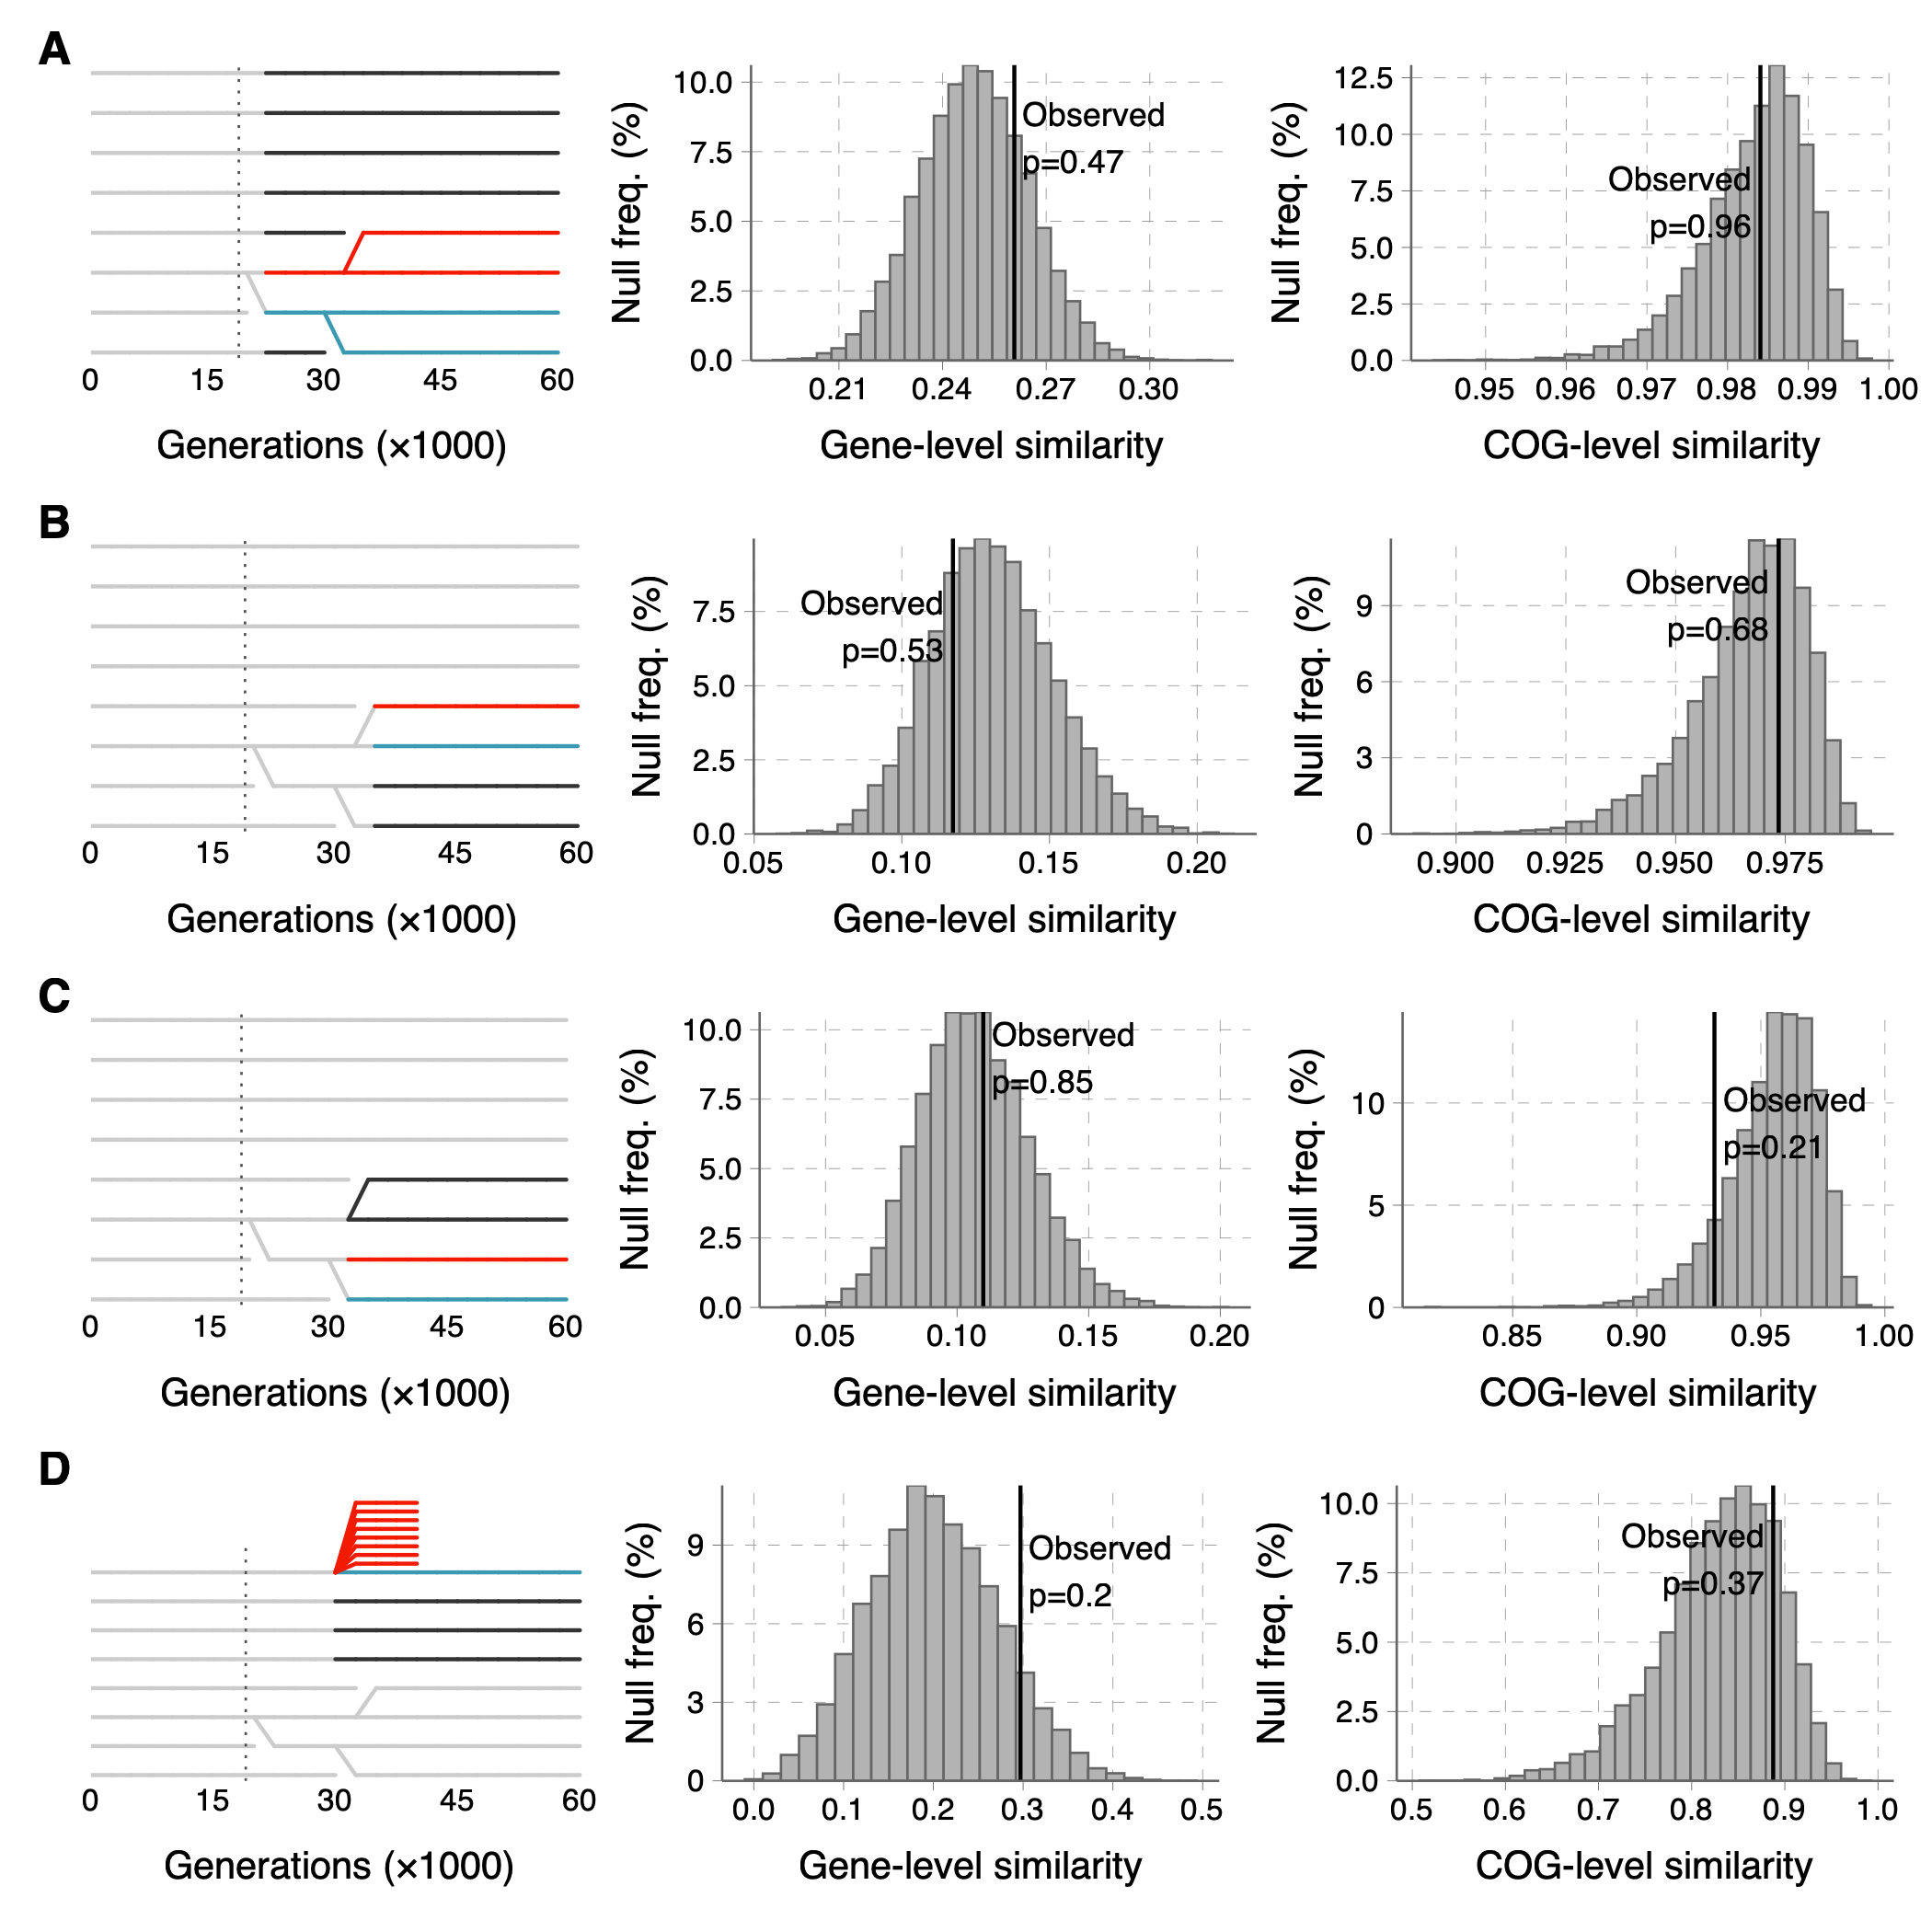

In [9]:
# Collage
letters = function(...){element_text(size = 12, hjust=0, vjust=0, face = 'bold', margin = margin(...))}
size(7, 7)

(
    ((tree_plot_FH + labs(tag='A')) + gene_plot_FH + cog_plot_FH) /
    ((tree_plot_FG + labs(tag='B')) + gene_plot_FG + cog_plot_FG) /
    ((tree_plot_HE + labs(tag='C')) + gene_plot_HE + cog_plot_HE) /
    ((tree_plot_A + labs(tag='D')) + gene_plot_A + cog_plot_A)
) +
    plot_layout() +
    plot_annotation() & theme(plot.tag = letters(-5, 5, 0, 0))

psave('Plots/convergence_across_contaminations_montage')